# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
try:
    env = gym.make("Taxi-v4", render_mode="rgb_array")
except gym.error.Error:
    # En versiones actuales de Gymnasium el entorno suele llamarse Taxi-v3.
    env = gym.make("Taxi-v3", render_mode="rgb_array")

print("Entorno:", env.spec.id)
print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)


Entorno: Taxi-v4
Número de estados: 500
Número de acciones: 6


### Pregunta 1 — Respuesta

Taxi tiene **500 estados y 6 acciones**. Tiene más estados que FrozenLake porque cada estado combina la posición del taxi, la ubicación del pasajero (incluido si ya está dentro del taxi) y su destino. Las seis acciones son sur, norte, este, oeste, recoger y dejar al pasajero.

## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 0
Nuevo estado: 486
Recompensa: -1
Terminated: False


### Pregunta 2 — Respuesta

En la salida de la celda anterior:

- \(s_t\): el número que aparece como **Estado**, antes de actuar.
- \(a_t\): el número que aparece como **Acción**, elegida aleatoriamente.
- \(r_{t+1}\): el valor que aparece como **Recompensa**, recibido tras actuar.
- \(s_{t+1}\): el número que aparece como **Nuevo estado**, después de la acción.

La recompensa y los estados concretos dependen de la acción aleatoria generada en esa ejecución.

## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3 — Respuesta

El agente aprende \( |\mathcal{S}|\times|\mathcal{A}|=500\times6=\mathbf{3000} \) valores Q: uno por cada combinación de estado y acción.

## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [5]:
def choose_action(Q, state, epsilon, env):
    # Explorar: escoger una acción aleatoria con probabilidad epsilon.
    if random.random() < epsilon:
        return env.action_space.sample()

    # Explotar: elegir una acción con el mayor valor Q.
    q_values = Q[state]
    best_actions = np.flatnonzero(q_values == np.max(q_values))
    return int(random.choice(best_actions))


## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [6]:
def update_q(Q, state, action, reward, next_state, alpha, gamma, terminated=False):
    # Si el episodio terminó, no se añade valor futuro.
    if terminated:
        target = reward
    else:
        target = reward + gamma * np.max(Q[next_state])

    # Error temporal-diferencia (TD).
    td_error = target - Q[state, action]

    # Actualización del valor Q.
    Q[state, action] += alpha * td_error


## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [7]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):
            # 1. Escoger acción con política epsilon-greedy.
            action = choose_action(Q, state, epsilon, env)

            # 2. Ejecutar la acción.
            next_state, reward, terminated, truncated, _ = env.step(action)

            # 3. Actualizar la Q-table.
            update_q(
                Q, state, action, reward, next_state,
                alpha, gamma, terminated=terminated
            )

            # 4. Actualizar estado y recompensa acumulada.
            total_reward += reward
            state = next_state

            # 5. Terminar si el episodio terminó o alcanzó el límite.
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards


## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [8]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


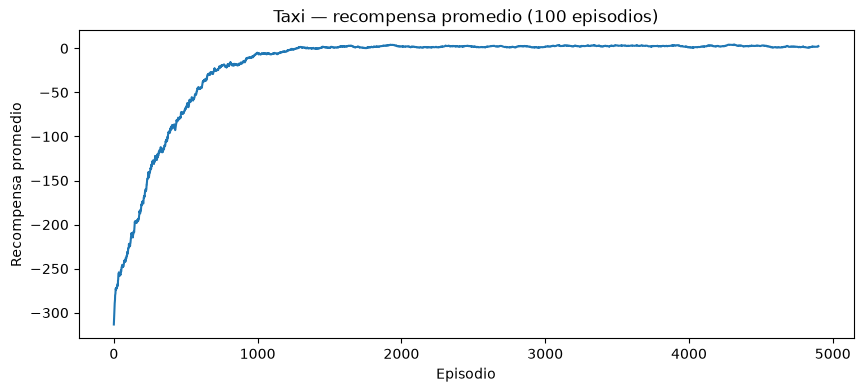

In [9]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi — recompensa promedio ({window} episodios)")
plt.show()


### Pregunta 4 — Respuesta orientativa

- La recompensa promedio normalmente **mejora** durante el entrenamiento: al principio suele ser muy negativa y después aumenta al aprender una ruta más eficiente.
- La estabilización depende de la semilla y de la ejecución. En 5000 episodios puede observarse una mejora clara en los primeros miles; escribe el episodio aproximado que veas en tu gráfica.
- La curva no demuestra necesariamente una convergencia perfecta. Indica que se aprendió una política razonablemente buena si la recompensa se mantiene alta y relativamente estable. Confirma el comportamiento con los episodios reproducidos.

## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [10]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [11]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


Recompensa total sin entrenamiento: -50


Ahora observe el agente entrenado.


In [12]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5 — Respuesta orientativa

- **Sin entrenamiento**, la Q-table contiene ceros, así que el taxi no tiene una preferencia aprendida y puede moverse sin un plan útil.
- Por lo general, el taxi sin entrenamiento no completa la tarea de forma fiable dentro del límite de pasos.
- **Después del entrenamiento**, el taxi debería recoger al pasajero, dirigirse al destino y dejarlo, con menos movimientos innecesarios.
- La evidencia visual es una secuencia de acciones más dirigida que termina con la entrega correcta del pasajero. La recompensa total también ayuda a comparar, aunque puede variar entre ejecuciones.

## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [13]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-2.19472859 -0.72556591 -0.91660937  3.94947757 -5.07844832 -6.45182002]
Mejor acción: 3


### Pregunta 6 — Respuesta

1. La acción con mayor valor Q es la que indica `np.argmax(Q_trained[state])`. Ejecuta la celda anterior y consulta el número. El significado es: 0 = sur, 1 = norte, 2 = este, 3 = oeste, 4 = recoger, 5 = dejar.
2. Un valor Q mayor indica que, según lo aprendido, esa acción tiene un retorno acumulado futuro esperado más alto desde ese estado.
3. No es solo la recompensa inmediata: \(Q(s,a)\) incorpora la recompensa actual y una estimación de las recompensas futuras, descontadas por el factor \(\gamma\).

## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar. En el ejemplo de abajo cambiamos únicamente `epsilon` de 0.1 a 0.3; se mantienen iguales `alpha`, `gamma` y el número de episodios.

### Pregunta 7 — Respuesta orientativa

Al aumentar epsilon, el agente explora más acciones aleatorias. Esto puede ayudar a descubrir rutas, pero también puede hacer que el aprendizaje sea menos estable y que la recompensa durante el entrenamiento sea más variable. La recompensa final no necesariamente mejora: hay que compararla con la ejecución original y observar la curva. Como epsilon se mantiene constante durante cada entrenamiento, incluso al final seguirá explorando con esa probabilidad.

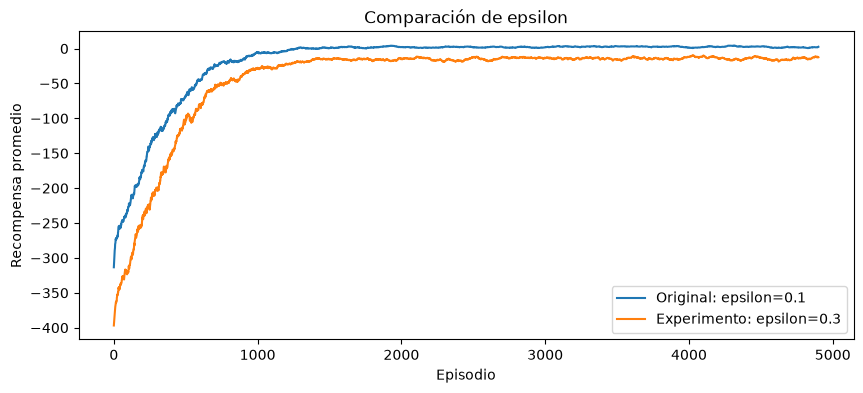

Promedio de recompensa, últimos 100 episodios (original): 2.57
Promedio de recompensa, últimos 100 episodios (experimento): -12.45


In [14]:
# Experimento: cambiar SOLO epsilon (0.1 -> 0.3)
Q_experiment, rewards_experiment = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.3
)

window = 100
avg_original = np.convolve(rewards, np.ones(window) / window, mode='valid')
avg_experiment = np.convolve(rewards_experiment, np.ones(window) / window, mode='valid')
plt.figure(figsize=(10, 4))
plt.plot(avg_original, label='Original: epsilon=0.1')
plt.plot(avg_experiment, label='Experimento: epsilon=0.3')
plt.xlabel('Episodio')
plt.ylabel('Recompensa promedio')
plt.title('Comparación de epsilon')
plt.legend()
plt.show()
print('Promedio de recompensa, últimos 100 episodios (original):', np.mean(rewards[-100:]))
print('Promedio de recompensa, últimos 100 episodios (experimento):', np.mean(rewards_experiment[-100:]))


### Conclusión

El experimento con **epsilon = 0.1** obtuvo una mejor recompensa promedio (2.57) que epsilon = 0.3 (-12.45). Además, su curva fue más estable. En esta ejecución, un menor nivel de exploración permitió aprovechar mejor lo aprendido y conseguir mejores resultados.